# Building Fake (AI-Generated) Image Detector Model Using Convolutional Neural Network with MobileNetV2

## Import Required Libraries

In [1]:
import tensorflow as tf
import numpy as np
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.models import load_model
import matplotlib.pyplot as plt

2025-05-20 04:42:34.024321: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1747716154.287416      35 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1747716154.362612      35 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


## Define Constants

In [2]:
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32
TRAIN_DIR = '/kaggle/input/140k-real-and-fake-faces/real_vs_fake/real-vs-fake/train'    # training image directory
VAL_DIR = '/kaggle/input/140k-real-and-fake-faces/real_vs_fake/real-vs-fake/valid'    # validation image directory

## Data Generators

Creates training and validation data loaders that automatically resize images and apply augmentations (like flips and zooms). This helps the model generalize better during training.

### Training Data Generator with Augmentation

In [3]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    horizontal_flip=True,
    zoom_range=0.2,
    rotation_range=10
)

In [4]:
train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

Found 100000 images belonging to 2 classes.


In [5]:
print(train_generator.class_indices)

{'fake': 0, 'real': 1}


### Validation Data Generator without Augmentation

In [6]:
val_datagen = ImageDataGenerator(rescale=1./255)

In [7]:
val_generator = val_datagen.flow_from_directory(
    VAL_DIR,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

Found 20000 images belonging to 2 classes.


## Build the CNN Model with MobileNetV2

Loads MobileNetV2 as a pre-trained CNN and freezes its layers so they’re not updated during training. Then, it adds custom layers on top (pooling, dropout, dense) to classify fake vs. real images.

In [8]:
base_model = MobileNetV2(
    weights='/kaggle/input/mobilenetv2/tensorflow2/default/1/mobilenet_v2_weights_tf_dim_ordering_tf_kernels_1.0_128_no_top.h5',
    include_top=False,
    input_shape=(*IMAGE_SIZE, 3))

base_model.trainable = False  # Freeze pre-trained layers

2025-05-20 04:44:05.628268: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [9]:
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')  # binary classification
])

## Compile the Model

Configures the model with the Adam optimizer, binary crossentropy loss (used for binary classification), and accuracy as a performance metric.

In [10]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [11]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_128 (Functional)    │ (None, 4, 4, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Early Stopping Callback

Early stopping prevents overfitting by monitoring validation accuracy and automatically stopping training when it stops improving. This helps the model generalize better and avoids unnecessary training time.

In [12]:
early_stop = EarlyStopping(
    monitor='val_accuracy',     
    patience=3,
    mode='max',
    verbose=1,
    restore_best_weights=True   # restore weights from best epoch
)

## Train the Model

Starts the training process using the training and validation generators for 20 epochs. This is where the model learns from the data.

In [13]:
history = model.fit(
    train_generator,
    epochs=20,
    validation_data=val_generator,
    callbacks=[early_stop]
)

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 1530s 487ms/step - accuracy: 0.6962 - loss: 0.5763 - val_accuracy: 0.7534 - val_loss: 0.5056
Epoch 2/20
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 1237s 396ms/step - accuracy: 0.7494 - loss: 0.5094 - val_accuracy: 0.7562 - val_loss: 0.4943
Epoch 3/20
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 1213s 388ms/step - accuracy: 0.7582 - loss: 0.4957 - val_accuracy: 0.7713 - val_loss: 0.4737
Epoch 4/20
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 1235s 395ms/step - accuracy: 0.7633 - loss: 0.4851 - val_accuracy: 0.7778 - val_loss: 0.4679
Epoch 5/20
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 1289s 412ms/step - accuracy: 0.7718 - loss: 0.4750 - val_accuracy: 0.7825 - val_loss: 0.4611
Epoch 6/20
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 1264s 404ms/step - accuracy: 0.7790 - loss: 0.4671 - val_accuracy: 0.7839 - val_loss: 0.4564
Epoch 7/20
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 1261s 404ms/step - accuracy: 0.7827 - loss: 0.4572 - val_accuracy: 0.7860 - val_loss: 0.4529
Epoch 8/20
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 1249s 400ms/s

## Save and Download the Trained Model

Saves the trained model to a `.h5` file, which includes both architecture and weights. This allows reuse later without retraining.

In [14]:
model.save('FP_fake_image_detector_modelV2.h5')

## Plot Accuracy/Loss

Plots training and validation accuracy/loss to visually monitor model performance over epochs. Helps detect overfitting or underfitting.

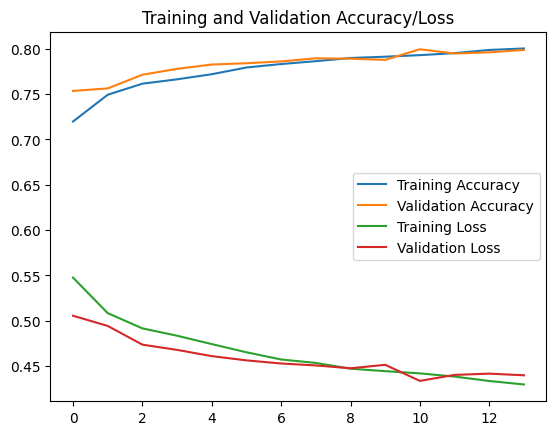

In [15]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title("Training and Validation Accuracy/Loss")
plt.show()